In [1]:
import os

from libraries.lns.wrapper.cvrp import load_data, ProblemState
from ortools.constraint_solver import pywrapcp, routing_enums_pb2
from problems.vrp.or_tools import run_ortools_vrp

def generate_better_solution_with_ortools(data, time_limit_seconds):

    solution, manager, routing = run_ortools_vrp(data, time_limit_seconds)

    routes = []
    for vehicle_id in range(data['num_vehicles']):
        index = routing.Start(vehicle_id)
        route = []
        while not routing.IsEnd(index):
            node_index = manager.IndexToNode(index)
            if node_index != data['depots']:
                route.append(node_index)
            index = solution.Value(routing.NextVar(index))
        routes.append(route)

    return ProblemState(routes, data), objective_trace, time_trace

os.environ["BASE_PATH"] = "/home/nico/KIT_IMI/multibay-reshuffling"

# Load data
data = load_data()

# Generate better solution with 30 seconds time limit (adjust as needed)
better_solution, objective_trace, time_trace = generate_better_solution_with_ortools(data, time_limit_seconds=60)

# Print routes and objective
print("Better solution routes and total distance:")
for i, route in enumerate(better_solution.routes):
    print(f"Vehicle {i + 1}: {route}")
print(f"Total distance: {better_solution.objective():.2f}")

/home/nico/.local/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:371: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)
/home/nico/anaconda3/envs/routefinder/lib/python3.10/site-packages/torchrl/data/tensor_specs.py:6294: DeprecationWarning: The BoundedTensorSpec has been deprecated and will be removed in v0.8. Please use Bounded instead.
  warnings.warn(
/home/nico/anaconda3/envs/routefinder/lib/python3.10/site-packages/torchrl/data/tensor_specs.py:6294: DeprecationWarning: The UnboundedDiscreteTensorSpec has been deprecated and will be removed in v0.8. Please use Unbounded instead.
  warnings.warn(
/home/nico/anaconda3/envs/routefinder/lib/python3.10/site-packages/torchrl/data/tensor_specs.py:6294: DeprecationWarning: The CompositeSpec has been deprecated and will be removed in v0.8. Please use Composite inst

NameError: name 'objective_trace' is not defined

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(time_trace, objective_trace)
plt.xlabel("Time (s)")
plt.ylabel("Objective Value")
plt.title(f"OR Tools Objective \n Best: {better_solution.objective()}")
plt.grid(True)
plt.tight_layout()
plt.show()

NameError: name 'time_trace' is not defined

<Figure size 1000x600 with 0 Axes>

In [21]:
better_solution.objective()

1127405

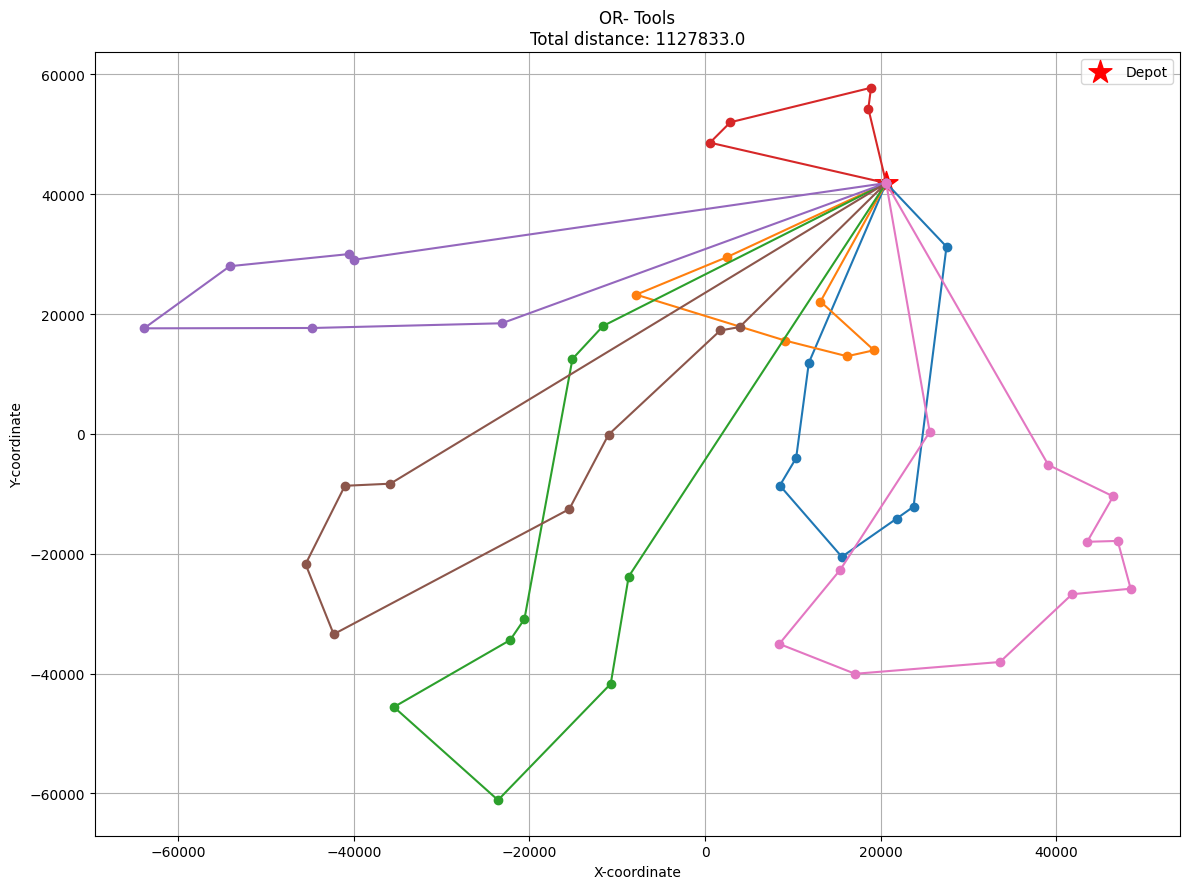

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.manifold import MDS

def plot_routes_from_distance_matrix(distance_matrix, routes, objective=-1, depot_index=0, title="ALNS", total_distance=None):
    mds = MDS(n_components=2, dissimilarity='precomputed', random_state=0)

    sym_matrix = (np.array(distance_matrix) + np.array(distance_matrix).T) / 2
    coordinates = mds.fit_transform(sym_matrix)

    plt.figure(figsize=(12, 9))

    for route in routes:
        if not route:
            continue
        full_route = [depot_index] + route + [depot_index]
        x = [coordinates[i][0] for i in full_route]
        y = [coordinates[i][1] for i in full_route]
        plt.plot(x, y, marker='o', linewidth=1.5)

    depot_x, depot_y = coordinates[depot_index]
    plt.scatter(depot_x, depot_y, c='red', marker='*', s=300, label="Depot")

    plt.xlabel("X-coordinate")
    plt.ylabel("Y-coordinate")
    plt.title(f"{title}\nTotal distance: {objective:.1f}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

plot_routes_from_distance_matrix(better_solution.data["distance_matrix"], better_solution.routes, better_solution.objective(), title="OR- Tools")